In [1]:
from scipy.optimize import brentq
import numpy as np
from datetime import datetime
import time, sys, os, pyvisa, subprocess
import matplotlib as mpl
import matplotlib.pyplot as plt
import time, math

In [2]:
hp34461a = 'GPIB0::22::INSTR'
vna_addr = 'GPIB0::16::INSTR'
port ='S21'

bkpower_addr = 'USB0::0x2EC7::0x9130::800885011797670040::INSTR'

In [3]:
from Instruments.hp34461A import *
from Instruments.vna_config import *
from Instruments.power_supply import*
from Routines.dep_evap import *
from Routines.res_to_temp import *
from Routines.retrieve_vna_data import *
from Routines.vna_analysis import *

3.7756
80
Started at 2026-05-15 13_16_31.269780
3.764
20
Started at 2026-05-15 13_17_03.383466


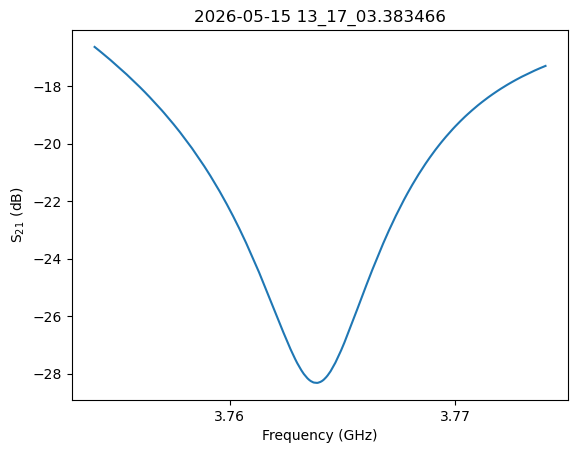

resonant Frequency: 3.7638266666666667 GHz
3.9609
80
Started at 2026-05-15 13_17_35.961302
3.9621
20
Started at 2026-05-15 13_18_08.087444


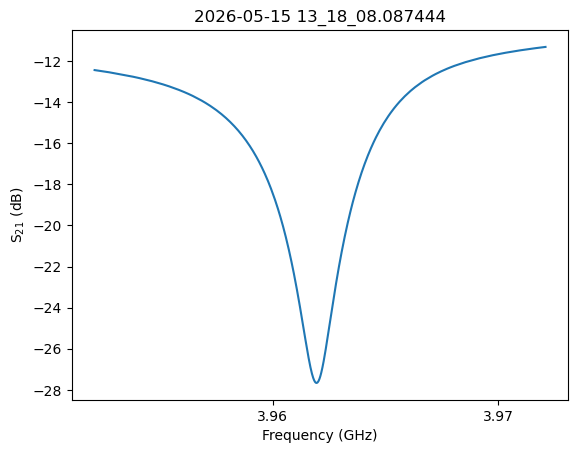

resonant Frequency: 3.96194 GHz
4.2583
80
Started at 2026-05-15 13_18_40.701051
4.2583
20
Started at 2026-05-15 13_19_12.803452


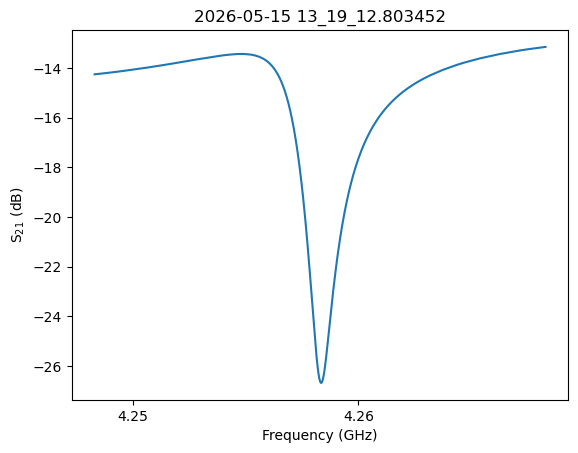

resonant Frequency: 4.258353333333334 GHz
4.4305
80
Started at 2026-05-15 13_19_45.371219
4.4281
20
Started at 2026-05-15 13_20_17.487179


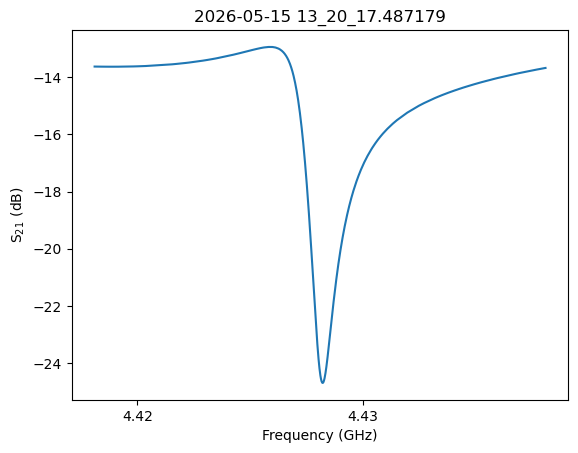

resonant Frequency: 4.42822 GHz
4.625
80
Started at 2026-05-15 13_20_50.051954
4.585
20
Started at 2026-05-15 13_21_22.174540


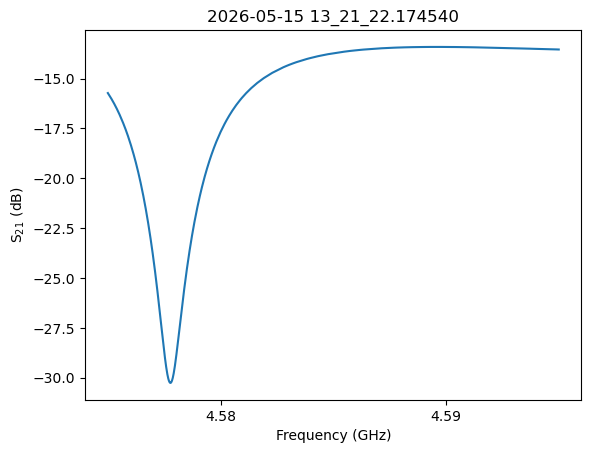

resonant Frequency: 4.577773333333333 GHz
4.8527
80
Started at 2026-05-15 13_21_54.754200
4.8375
20
Started at 2026-05-15 13_22_26.876930


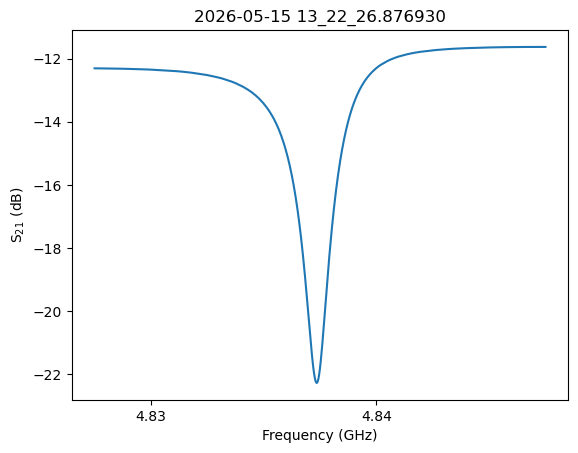

resonant Frequency: 4.837353333333333 GHz
5.163
80
Started at 2026-05-15 13_22_59.448715
5.1614
20
Started at 2026-05-15 13_23_31.560257


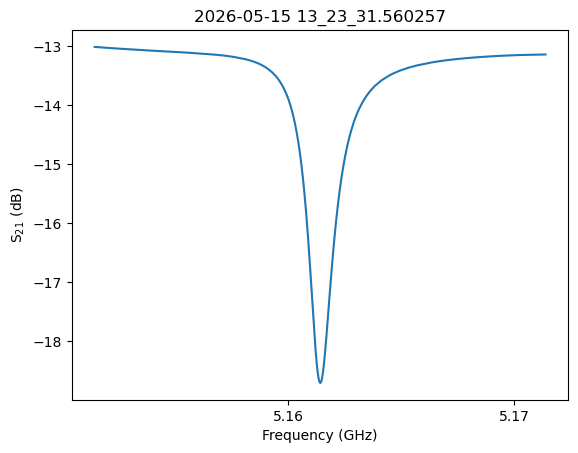

resonant Frequency: 5.161413333333333 GHz
5.404
80
Started at 2026-05-15 13_24_04.132663
5.4016
20
Started at 2026-05-15 13_24_36.251875


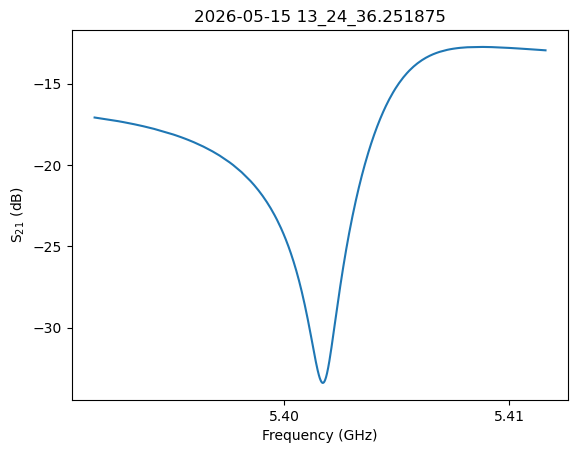

resonant Frequency: 5.40172 GHz
5.5898
80
Started at 2026-05-15 13_25_08.814110
5.5882
20
Started at 2026-05-15 13_25_40.933771


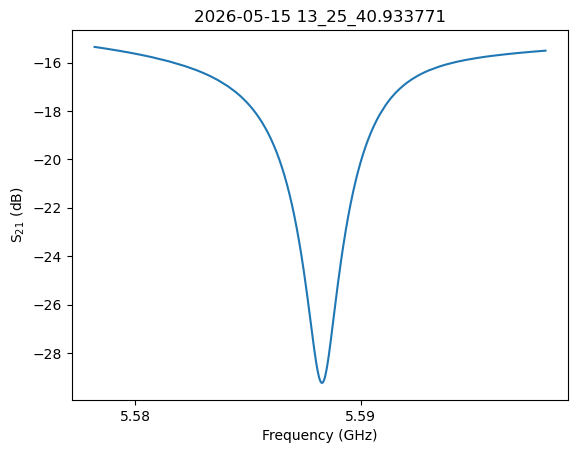

resonant Frequency: 5.58828 GHz


In [5]:
os.makedirs(r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\aftersinglescan_05152026", exist_ok= True)

path = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\aftersinglescan_05152026"


f_search = [3.7756, 3.9609, 4.2583, 4.4305, 4.625, 4.8527, 5.163, 5.404, 5.5898]

multires_s21_scan(vna_addr, data_dir= path, f_search = f_search, span = 20, name = '18K', to_save = True)

3.76004


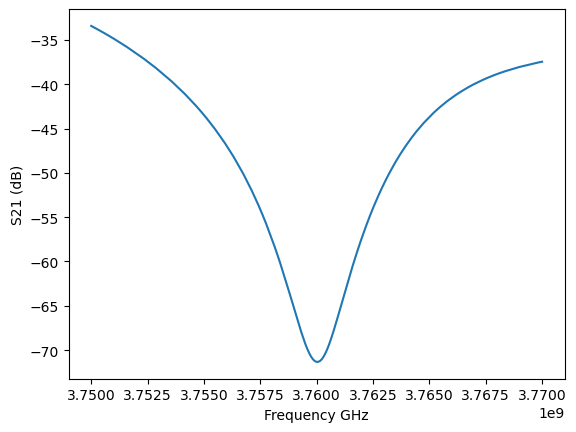

3.9561133333333336


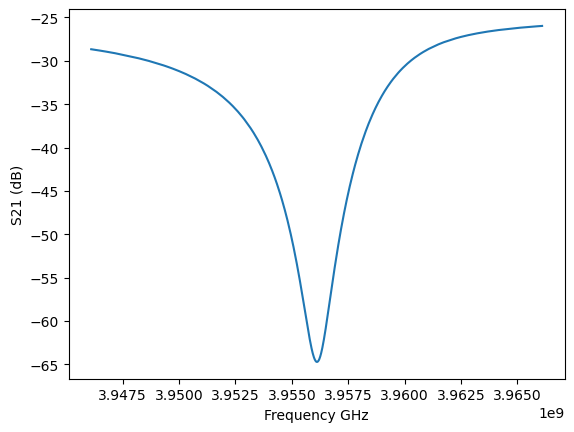

4.251966666666666


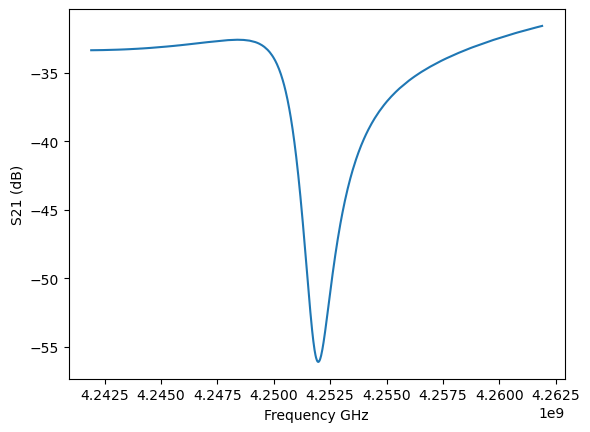

4.421673333333333


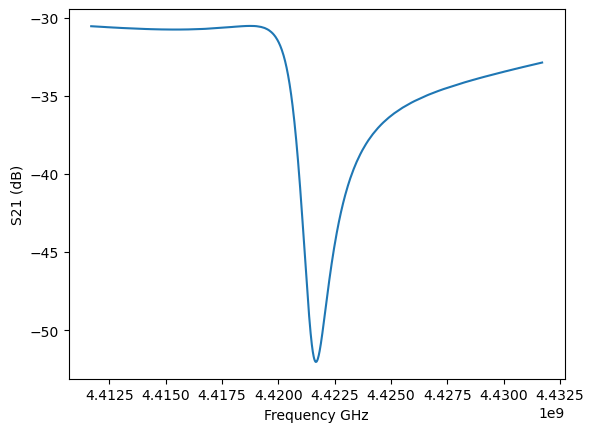

4.600506666666667


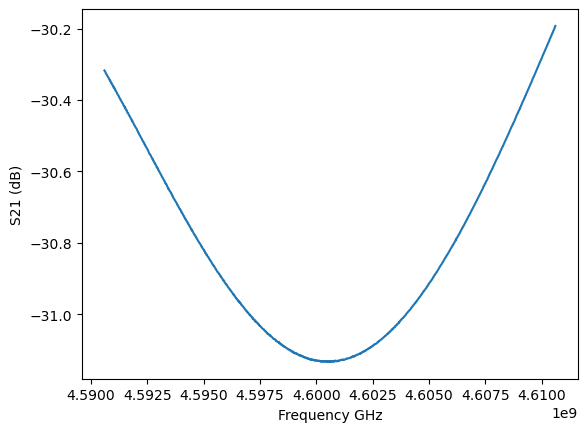

4.830353333333333


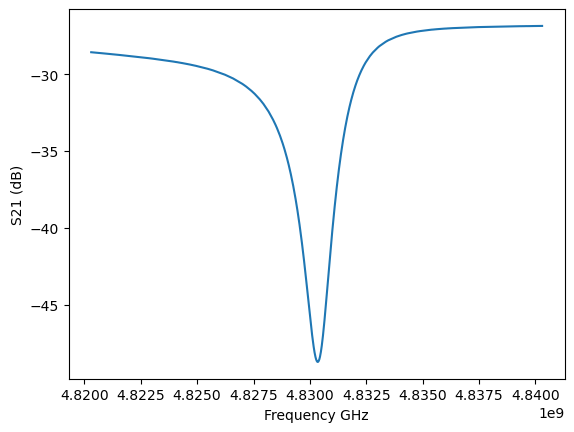

5.153826666666667


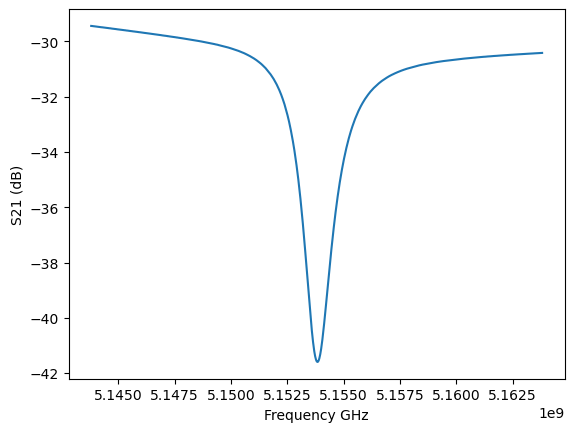

5.393626666666667


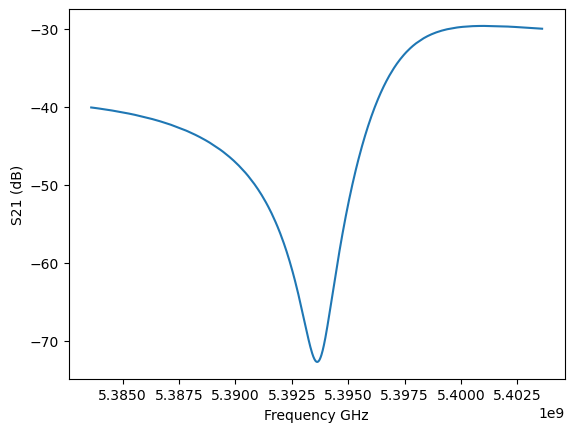

5.579853333333333


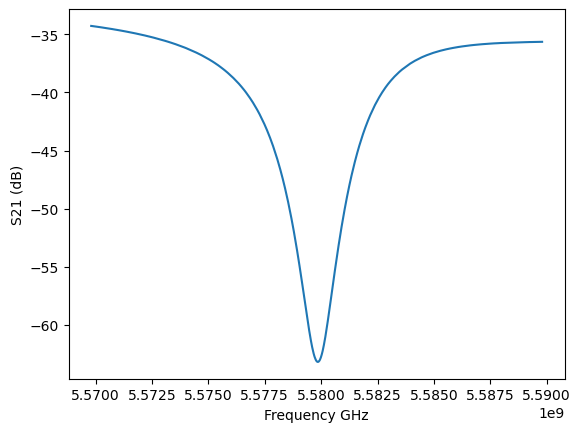

In [11]:
dir = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\beforesinglescan_05132026"

f0_list = []

for file in os.listdir(dir):
    df = pd.read_csv(dir + "\\" + file)
    frequency = df.iloc[0, 1:].to_numpy()
    real = df.iloc[1, 1:].to_numpy()
    imag = df.iloc[2, 1:].to_numpy()

    s21 = 20*np.log(np.sqrt(real**2 + imag**2))
    fmin = frequency[np.argmin(s21)]/1E9
    print(fmin)
    f0_list.append(fmin)
    plt.plot(frequency, s21)
    plt.xlabel("Frequency GHz")
    plt.ylabel("S21 (dB)")
    plt.show()

f0_list = np.array(f0_list)



3.7638266666666667


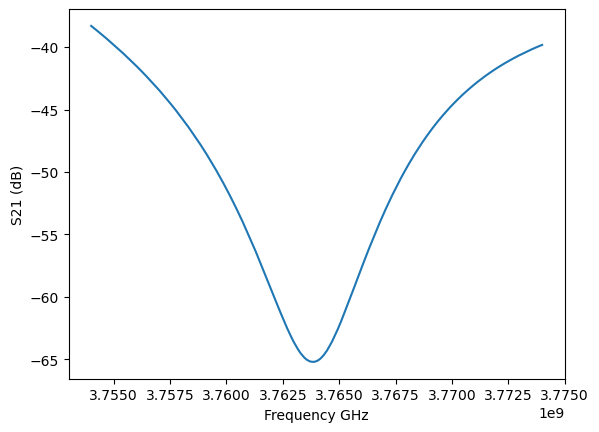

3.96194


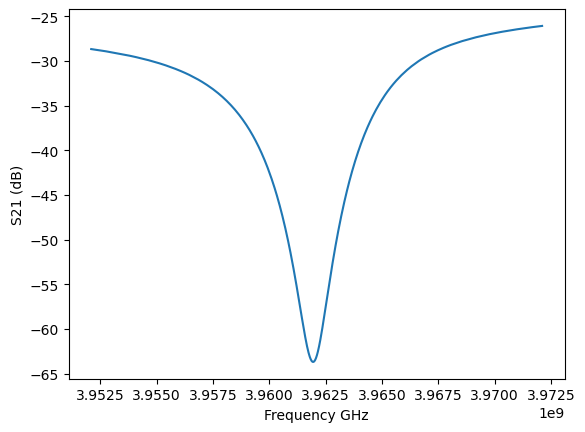

4.258353333333334


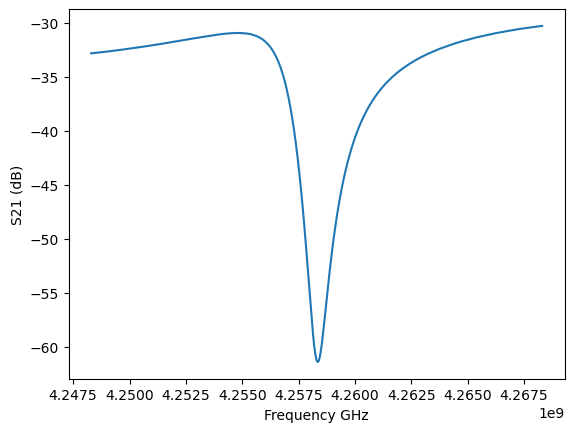

4.42822


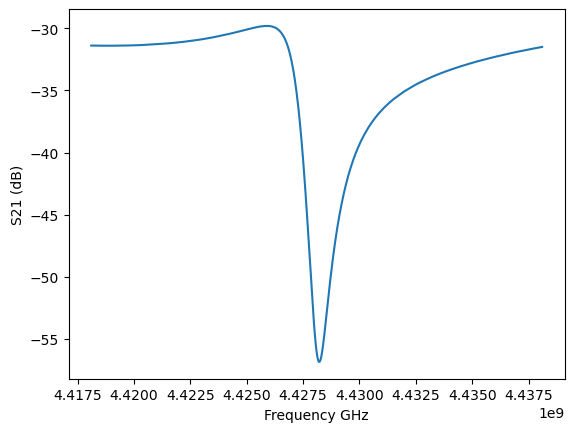

4.577773333333333


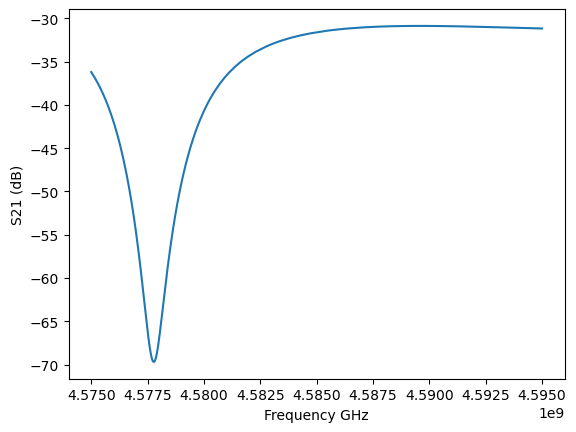

4.837353333333333


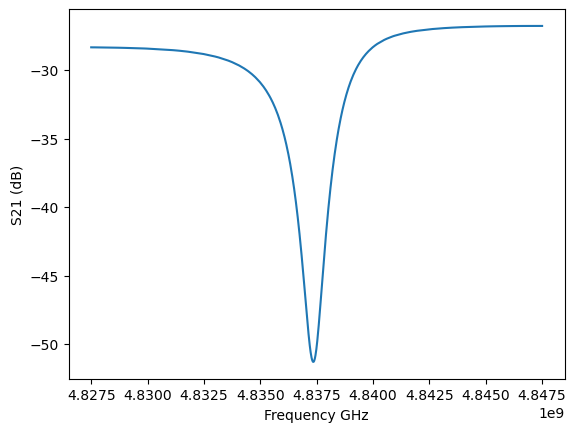

5.161413333333333


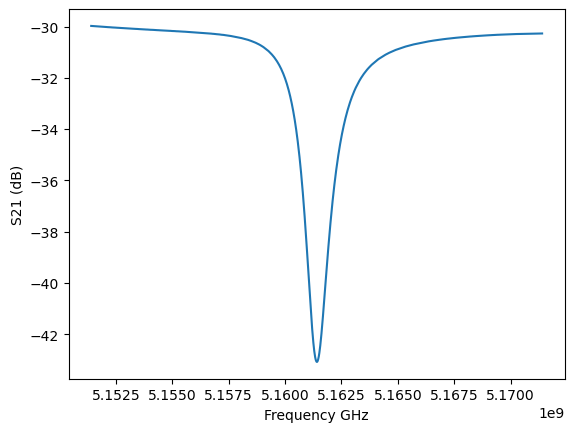

5.40172


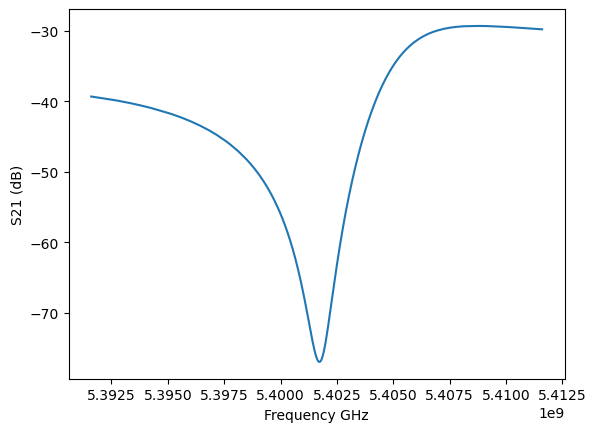

5.58828


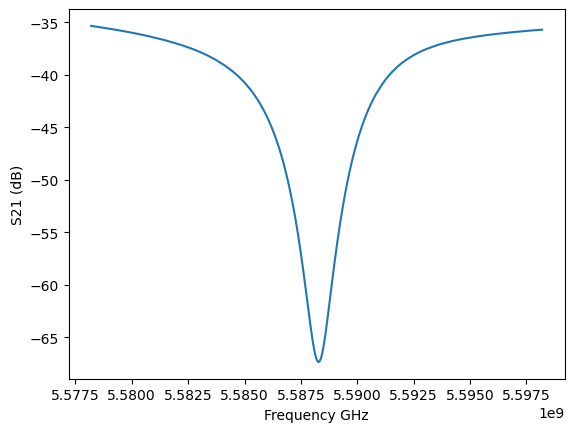

In [12]:
dir = r"C:\Users\crow104\Desktop\IceT_SD\SpatialNeon\Data\aftersinglescan_05152026"

f0_list2 = []

for file in os.listdir(dir):
    df = pd.read_csv(dir + "\\" + file)
    frequency = df.iloc[0, 1:].to_numpy()
    real = df.iloc[1, 1:].to_numpy()
    imag = df.iloc[2, 1:].to_numpy()

    s21 = 20*np.log(np.sqrt(real**2 + imag**2))
    fmin = frequency[np.argmin(s21)]/1E9
    print(fmin)
    f0_list2.append(fmin)
    plt.plot(frequency, s21)
    plt.xlabel("Frequency GHz")
    plt.ylabel("S21 (dB)")
    plt.show()


In [16]:
normalized = ((f0_list-f0_list2)/f0_list)*100
df = pd.DataFrame({
    "before": f0_list,
    "after": f0_list2,
    "percentage change": normalized
})

print(df)

     before     after  percentage change
0  3.760040  3.763827          -0.100708
1  3.956113  3.961940          -0.147283
2  4.251967  4.258353          -0.150205
3  4.421673  4.428220          -0.148059
4  4.600507  4.577773           0.494148
5  4.830353  4.837353          -0.144917
6  5.153827  5.161413          -0.147205
7  5.393627  5.401720          -0.150054
8  5.579853  5.588280          -0.151020
